# 04. One-stage anchor-free detector: YOLO11

**Question.** How does an anchor-free detector with task-aligned assignment compare with the anchor-based ones on small and dense objects, and which input resolution, head and data changes help?

**Protocol** as in notebook 02: fold 0, every 5th training frame, long side 1280, 12 epochs, COCO-pretrained weights, test-like downscaled scored windows, ignored regions as crowd. Model: Ultralytics YOLO11 (decoupled head, distribution focal loss, task-aligned assigner).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

os.environ.setdefault("VISDET_DATA", "../../hw2/data")
RUNS = Path(os.environ.get("VISDET_RUNS", "../../hw2/runs"))
from visdet.data.index import load_tables
from visdet.viz import gallery, results, style

style.apply()
tables = load_tables()

## Experiments
| run | change from yolo11s at 1280 |
|---|---|
| yolo11s-960 / yolo11s-1536 | input resolution (search range 960-1536) |
| yolo11s-downscale (+ mild / strong) | training images shrunk and enlarged back with probability 0.5 to scale 0.35-1 (mild 0.6-1, strong p 0.8 to 0.25-1), mimicking the 680-960 px test frames |
| yolo11m / yolo11l (+ downscale) | larger models |

In [2]:
results.run_table(
    RUNS,
    [
        "yolo11s",
        "yolo11s-960",
        "yolo11s-1536",
        "yolo11s-downscale",
        "yolo11s-ds-mild",
        "yolo11s-ds-strong",
        "yolo11m",
        "yolo11m-downscale",
        "yolo11l",
        "yolo11l-downscale",
        "faster-rcnn-proposals",
        "retinanet-focal",
    ],
)

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,ms_per_image
yolo11s,0.2322,0.4273,0.2223,0.0678,0.2169,0.3446,12.6
yolo11s-960,0.2206,0.3923,0.2166,0.0667,0.1969,0.3329,11.3
yolo11s-1536,0.2367,0.4174,0.2344,0.0719,0.2217,0.3528,15.2
yolo11s-downscale,0.2447,0.4390,0.2419,0.0677,0.2072,0.3779,12.5
yolo11s-ds-mild,0.2431,0.4287,0.2430,0.0556,0.2095,0.3811,12.5
yolo11s-ds-strong,0.2350,0.4126,0.2352,0.0595,0.2096,0.3538,12.5
yolo11m,0.2603,0.4637,0.2570,0.0623,0.2334,0.3812,13.7
yolo11l,0.2532,0.4677,0.2375,0.0721,0.2262,0.3581,14.8
yolo11l-downscale,0.2682,0.4661,0.2666,0.0641,0.2137,0.4086,14.5
faster-rcnn-proposals,0.2486,0.4585,0.2387,0.0477,0.2024,0.4067,22.7


## Validation mAP over training (Ultralytics evaluator, no ignored regions)

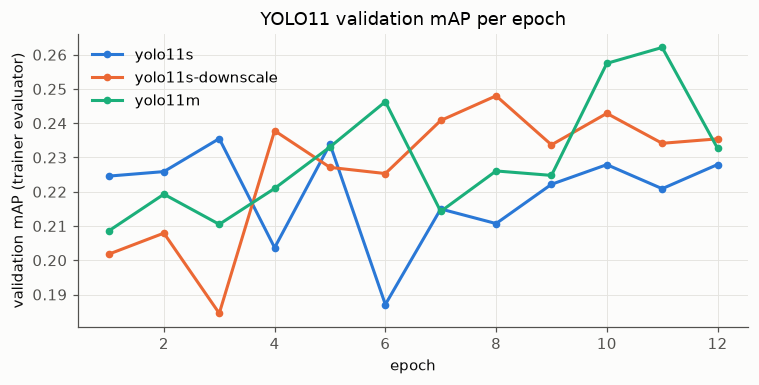

In [3]:
curves = {
    name: results.ultralytics_curve(RUNS, name)
    for name in ["yolo11s", "yolo11s-downscale", "yolo11m"]
}
fig = results.plot_curves(curves, "YOLO11 validation mAP per epoch")

## Results by object size against the tuned anchor-based detectors

side,<16,16-32,32-64,64-96,>=96
faster-rcnn-proposals,0.005,0.296,0.547,0.712,0.850
retinanet-focal,0.002,0.234,0.491,0.718,0.887
yolo11s,0.017,0.300,0.546,0.692,0.784
yolo11m,0.003,0.248,0.533,0.708,0.857


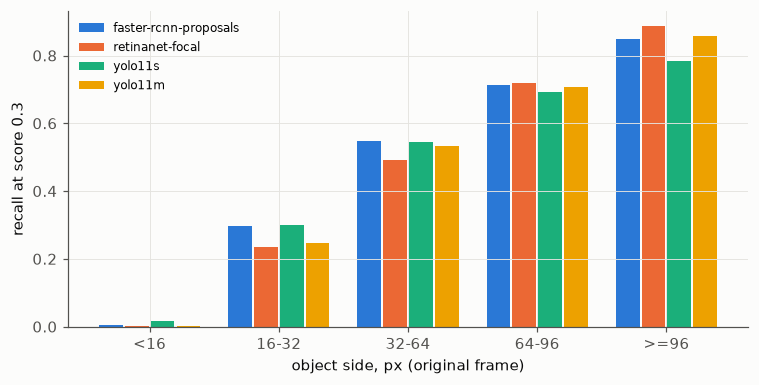

In [4]:
breakdowns = {}
for name in ["faster-rcnn-proposals", "retinanet-focal", "yolo11s", "yolo11m"]:
    pred = pd.read_parquet(RUNS / name / "fold0" / "val_predictions.parquet")
    breakdowns[name], _ = results.error_breakdown(tables, pred)
fig = results.plot_size_recall(breakdowns)
pd.DataFrame({k: v["recall"] for k, v in breakdowns.items()}).T

## Errors and failure cases of the best YOLO

background         10300
class confusion    10236
localisation        6872
duplicate            397
Name: count, dtype: int64

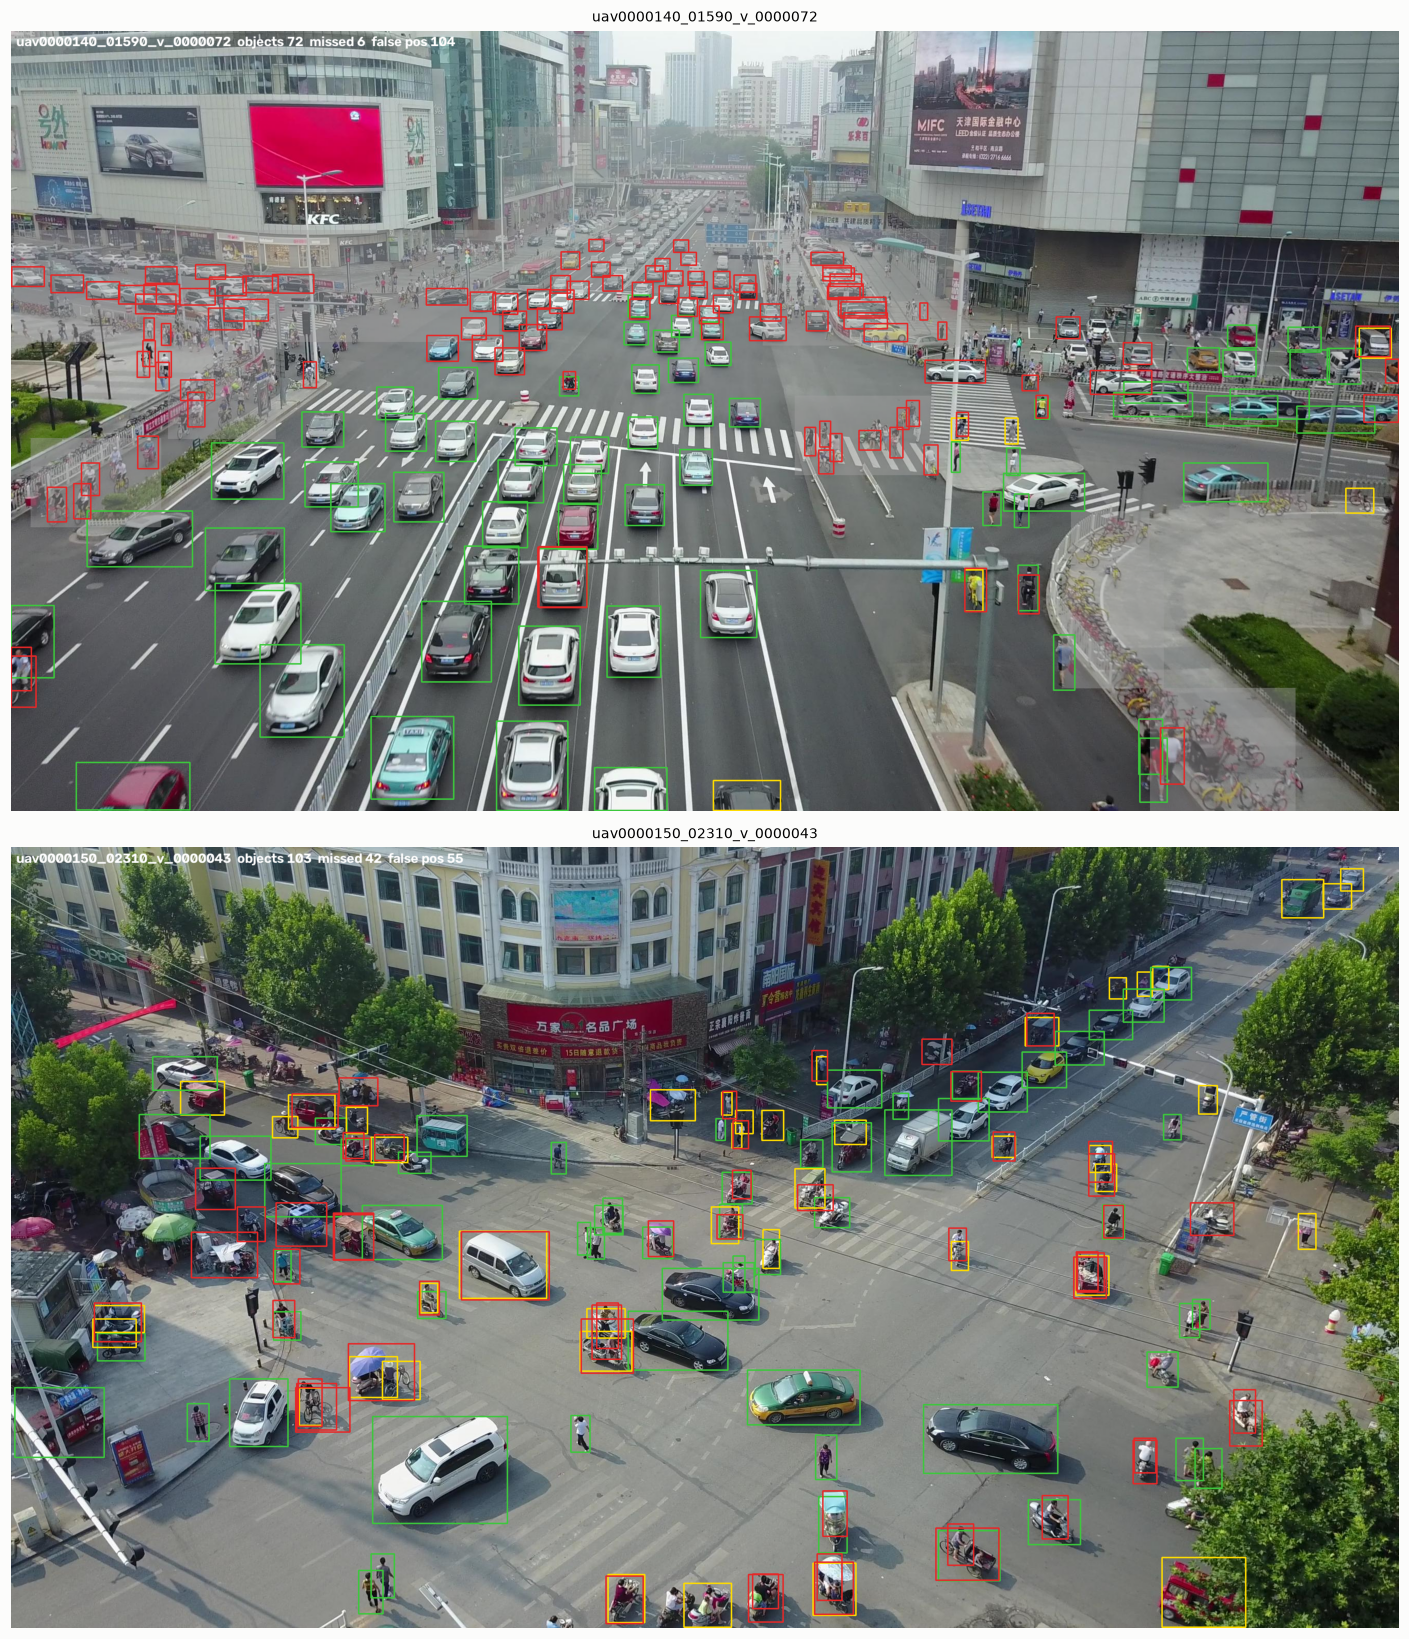

In [5]:
pred = pd.read_parquet(RUNS / "yolo11m" / "fold0" / "val_predictions.parquet")
_, fp_kinds = results.error_breakdown(tables, pred)
display(fp_kinds)
worst = results.worst_frames(tables, pred, n=2)
fig, axes = plt.subplots(2, 1, figsize=(13, 15))
for ax, image_id in zip(axes, worst["image_id"], strict=False):
    ax.imshow(gallery.render(tables, pred, image_id, threshold=0.3)[:, :, ::-1])
    ax.set_title(image_id, fontsize=9)
    ax.axis("off")
fig.tight_layout()

## Conclusions
- Without anchors, YOLO11 assigns each object to the grid points inside it ranked by a task-aligned score (classification x IoU), so tiny objects compete for very few points on the stride-8 grid.
- Input resolution matters little between 1280 and 1536 (+0.005) and 960 is clearly worse.
- Model size matters more: yolo11m is 0.028 above yolo11s; yolo11l does not add more.
- Downscale augmentation helps the small and large model on this validation (+0.013 / +0.015) but not yolo11m; on the degraded validation of notebook 06 it helps all of them.
- Compared with the anchor-based detectors, yolo11m is better in mAP but finds fewer 16-32 px objects at a fixed score threshold than Faster R-CNN.